## Redes Neurais Artificiais 2026.2

- **Disciplina**: Redes Neurais Artificiais 2026.2
- **Professora**: Elloá B. Guedes (ebgcosta@uea.edu.br)  
- **Github**: http://github.com/elloa
- **Alunos**: Bernardo Gontijo (bgfe.eng24@uea.edu.br), Mateus Cabral (mcpi.eng24@uea.edu.br) e Matheus Amazonas (meac.eng24@uea.edu.br) 
        

Levando em conta a base de dados **_Dry Bean Dataset_**, esta segunda parte do Projeto Prático 2.2 diz respeito à proposição e avaliação de múltiplas redes neurais artificiais do tipo Feedforward Multilayer Perceptron para o problema da classificação multiclasse de variedades de feijão seco a partir de características geométricas extraídas de imagens dos grãos.

## Testando Redes Neurais com os Atributos Numéricos

1. Abra a base de dados em questão
2. Verifique que todos os atributos preditores são numéricos. O único atributo categórico é o alvo (`Class`), que não deve entrar em X
3. Armazene o atributo alvo em uma variável y e os atributos preditores em uma variável X
4. Efetue uma partição holdout 70/30 com o sklearn, distribuindo os exemplos de maneira aleatória e estratificada (`stratify=y`), com `random_state` fixo para reprodutibilidade
5. Efetue o escalonamento dos atributos


In [1]:
import numpy as np
import pandas as pd

from pathlib import Path
from joblib import Parallel, delayed, parallel_config, cpu_count
from threadpoolctl import threadpool_limits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import classification_report
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score, 
    f1_score, 
    precision_score, 
    recall_score
)

import matplotlib.pyplot as plt

In [2]:
raiz = Path.cwd()
if raiz.name == "Notebooks":
    raiz = raiz.parent

df = pd.read_excel(raiz / "DryBeanDataset" / "Dry_Bean_Dataset.xlsx")

In [3]:
df.dtypes

Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRation       float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
Class                  str
dtype: object

In [4]:
y = df["Class"]
y.head()

0    SEKER
1    SEKER
2    SEKER
3    SEKER
4    SEKER
Name: Class, dtype: str

In [5]:
X = df.drop("Class", axis=1)
X.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166


Reservamos 30% da base como teste final da etapa 3. Os holdouts desta etapa usam os 70% restantes, de modo que o teste final fique fora da seleção das arquiteturas.

In [6]:
# Separação externa, usada também no notebook da etapa 3.
X_base, X_final, y_base, y_final = train_test_split(
    X, y, test_size=0.3, random_state=64, stratify=y
)

# Holdout da primeira rede, dentro da base de desenvolvimento.
X_train, X_test, y_train, y_test = train_test_split(
    X_base, y_base, test_size=0.3, random_state=64, stratify=y_base
)

### Escalonando os atributos

O treinamento de uma rede neural artificial é mais eficiente quando os valores que lhes são fornecidos como entrada são pequenos e estão em escalas semelhantes, pois isto favorece a convergência. Isto é feito escalonando-se os atributos, mas precisa ser feito de maneira cautelosa, para que informações do conjunto de teste não sejam fornecidas no treinamento.

Há duas estratégias para tal escalonamento: normalização (que leva os valores ao intervalo [0,1]) e padronização (que centraliza os dados em média 0 e desvio padrão 1). Ambas possuem características particulares, vantagens e limitações, como é possível ver aqui: https://www.analyticsvidhya.com/blog/2020/04/feature-scaling-machine-learning-normalization-standardization/

No nosso caso, vamos usar a padronização. Assim, com os atributos preditores do treinamento, isto é, X_train, deve-se subtrair a média e dividir pelo desvio padrão. Para tanto, use o StandardScaler e ajuste-o com os dados do conjunto de treino (fit), transformando-os em seguida (transform). Depois, apenas transforme os dados do conjunto de teste (transform), usando a média e o desvio padrão calculados no treino, sem chamar o fit novamente.

Se todo o conjunto X for utilizado na padronização, a rede neural receberá informações do conjunto de teste por meio da média e do desvio padrão utilizados para preparar os dados de treinamento, o que não é desejável (vazamento de dados, ou *data leakage*).

In [7]:
scaler = StandardScaler()
scaler.fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

### Continuando

1. Treine uma rede neural multilayer perceptron para este problema com uma única camada oculta de dez neurônios  
    1.1 Utilize a função de ativação ReLU  
    1.2 Utilize o solver Adam    
    1.3 Imprima o passo a passo do treinamento  
    1.4 Utilize o número máximo de épocas igual a 300
2. Com o modelo em questão, após o treinamento, apresente os resultados para o conjunto de teste:  
    2.1 Matriz de confusão  
    2.2 Acurácia  
    2.3 F-Score (F1)  
    2.4 Precisão  
    2.5 Revocação   
3. Repita o treinamento da mesma rede anterior sem imprimir o passo a passo por 10 vezes  
    3.1 Cada uma destas repetições deve ser feita com uma nova partição holdout 70/30 estratificada, e o escalonamento deve ser reajustado com os dados de treino de cada partição  
    3.2 Apresente a média e o desvio padrão da acurácia e do F-Score para o conjunto de teste  
4. Repita por 10 vezes o treinamento desta mesma rede, mas utilizando o otimizador SGD, com as mesmas 10 partições do item anterior  
    4.1 Apresente a média e o desvio padrão da acurácia e do F-Score para o conjunto de teste  
5. Houve influência da escolha do otimizador no desempenho da rede? Justifique com as médias e os desvios padrão obtidos

### **1. Treine uma rede neural multilayer perceptron para este problema com uma única camada oculta de dez neurônios**

In [8]:
mlp = MLPClassifier(
    hidden_layer_sizes=(10,),
    activation="relu",
    solver="adam",
    max_iter=300,
    random_state=64,
    verbose=True
)

In [9]:
with threadpool_limits(limits=1, user_api="blas"):
    mlp.fit(X_train, y_train)

Iteration 1, loss = 2.13444325
Iteration 2, loss = 1.71694635
Iteration 3, loss = 1.40921646
Iteration 4, loss = 1.20480950
Iteration 5, loss = 1.07103647
Iteration 6, loss = 0.96925294
Iteration 7, loss = 0.88192626
Iteration 8, loss = 0.80522453
Iteration 9, loss = 0.73828743
Iteration 10, loss = 0.68061794
Iteration 11, loss = 0.63101475
Iteration 12, loss = 0.58820572
Iteration 13, loss = 0.55116297
Iteration 14, loss = 0.51903609
Iteration 15, loss = 0.49090746
Iteration 16, loss = 0.46608669
Iteration 17, loss = 0.44367565
Iteration 18, loss = 0.42362807
Iteration 19, loss = 0.40555511
Iteration 20, loss = 0.38925417
Iteration 21, loss = 0.37455942
Iteration 22, loss = 0.36132388
Iteration 23, loss = 0.34905978
Iteration 24, loss = 0.33823392
Iteration 25, loss = 0.32825705
Iteration 26, loss = 0.31933850
Iteration 27, loss = 0.31126772
Iteration 28, loss = 0.30350138
Iteration 29, loss = 0.29671802
Iteration 30, loss = 0.29045478
Iteration 31, loss = 0.28448139


Iteration 32, loss = 0.27929669
Iteration 33, loss = 0.27433826
Iteration 34, loss = 0.26972264
Iteration 35, loss = 0.26520478
Iteration 36, loss = 0.26120869
Iteration 37, loss = 0.25737949
Iteration 38, loss = 0.25388027
Iteration 39, loss = 0.25047660
Iteration 40, loss = 0.24720745
Iteration 41, loss = 0.24440309
Iteration 42, loss = 0.24141672
Iteration 43, loss = 0.23887830
Iteration 44, loss = 0.23623765
Iteration 45, loss = 0.23387170
Iteration 46, loss = 0.23157683
Iteration 47, loss = 0.22937097
Iteration 48, loss = 0.22737323
Iteration 49, loss = 0.22539620
Iteration 50, loss = 0.22351413
Iteration 51, loss = 0.22208286
Iteration 52, loss = 0.22023734
Iteration 53, loss = 0.21877402
Iteration 54, loss = 0.21710905
Iteration 55, loss = 0.21594236
Iteration 56, loss = 0.21471265
Iteration 57, loss = 0.21322306
Iteration 58, loss = 0.21216771
Iteration 59, loss = 0.21121148
Iteration 60, loss = 0.21019886
Iteration 61, loss = 0.20920363
Iteration 62, loss = 0.20833076
Iteratio

Iteration 65, loss = 0.20630192
Iteration 66, loss = 0.20576041
Iteration 67, loss = 0.20535919
Iteration 68, loss = 0.20483656
Iteration 69, loss = 0.20412215
Iteration 70, loss = 0.20355683
Iteration 71, loss = 0.20319923
Iteration 72, loss = 0.20282778
Iteration 73, loss = 0.20227419
Iteration 74, loss = 0.20186449
Iteration 75, loss = 0.20139724
Iteration 76, loss = 0.20101209
Iteration 77, loss = 0.20098298
Iteration 78, loss = 0.20044142
Iteration 79, loss = 0.20011378
Iteration 80, loss = 0.19982425
Iteration 81, loss = 0.19958280
Iteration 82, loss = 0.19914510
Iteration 83, loss = 0.19896320
Iteration 84, loss = 0.19875531
Iteration 85, loss = 0.19856471
Iteration 86, loss = 0.19842270
Iteration 87, loss = 0.19816847
Iteration 88, loss = 0.19788021
Iteration 89, loss = 0.19746819
Iteration 90, loss = 0.19739189
Iteration 91, loss = 0.19726328
Iteration 92, loss = 0.19684366
Iteration 93, loss = 0.19650021
Iteration 94, loss = 0.19640841
Iteration 95, loss = 0.19626788
Iteratio

Iteration 97, loss = 0.19597279
Iteration 98, loss = 0.19574221
Iteration 99, loss = 0.19565203
Iteration 100, loss = 0.19559649
Iteration 101, loss = 0.19525945
Iteration 102, loss = 0.19518253
Iteration 103, loss = 0.19520220
Iteration 104, loss = 0.19491362
Iteration 105, loss = 0.19489908
Iteration 106, loss = 0.19460030
Iteration 107, loss = 0.19426034
Iteration 108, loss = 0.19430107
Iteration 109, loss = 0.19428790
Iteration 110, loss = 0.19405957
Iteration 111, loss = 0.19378276
Iteration 112, loss = 0.19372460
Iteration 113, loss = 0.19380265
Iteration 114, loss = 0.19357774
Iteration 115, loss = 0.19335714
Iteration 116, loss = 0.19350200
Iteration 117, loss = 0.19319842
Iteration 118, loss = 0.19308728
Iteration 119, loss = 0.19317659
Iteration 120, loss = 0.19298171
Iteration 121, loss = 0.19280096
Iteration 122, loss = 0.19282797
Iteration 123, loss = 0.19302351
Iteration 124, loss = 0.19232067
Iteration 125, loss = 0.19239443
Iteration 126, loss = 0.19209823
Iteration 127

Iteration 130, loss = 0.19186015
Iteration 131, loss = 0.19182805
Iteration 132, loss = 0.19180015
Iteration 133, loss = 0.19159914
Iteration 134, loss = 0.19136616
Iteration 135, loss = 0.19145325
Iteration 136, loss = 0.19132525
Iteration 137, loss = 0.19112598
Iteration 138, loss = 0.19091263
Iteration 139, loss = 0.19097563
Iteration 140, loss = 0.19089979
Iteration 141, loss = 0.19109974
Iteration 142, loss = 0.19071080
Iteration 143, loss = 0.19060687
Iteration 144, loss = 0.19065124
Iteration 145, loss = 0.19085672
Iteration 146, loss = 0.19079539
Iteration 147, loss = 0.19032543
Iteration 148, loss = 0.19041163
Iteration 149, loss = 0.19046164
Iteration 150, loss = 0.18999289
Iteration 151, loss = 0.18984683
Iteration 152, loss = 0.19008360
Iteration 153, loss = 0.18970758
Iteration 154, loss = 0.18972933
Iteration 155, loss = 0.18958677
Iteration 156, loss = 0.18954674
Iteration 157, loss = 0.18942449
Iteration 158, loss = 0.18965088
Iteration 159, loss = 0.18959952
Iteration 

Iteration 162, loss = 0.18947905
Iteration 163, loss = 0.18921142
Iteration 164, loss = 0.18919783
Iteration 165, loss = 0.18901916
Iteration 166, loss = 0.18923049
Iteration 167, loss = 0.18890134
Iteration 168, loss = 0.18877224
Iteration 169, loss = 0.18860836
Iteration 170, loss = 0.18874965
Iteration 171, loss = 0.18852869
Iteration 172, loss = 0.18879954
Iteration 173, loss = 0.18865363
Iteration 174, loss = 0.18848601
Iteration 175, loss = 0.18813686
Iteration 176, loss = 0.18831273
Iteration 177, loss = 0.18819974
Iteration 178, loss = 0.18810675
Iteration 179, loss = 0.18812075
Iteration 180, loss = 0.18783757
Iteration 181, loss = 0.18764547
Iteration 182, loss = 0.18765875
Iteration 183, loss = 0.18785710
Iteration 184, loss = 0.18763635
Iteration 185, loss = 0.18741154
Iteration 186, loss = 0.18757025
Iteration 187, loss = 0.18727727
Iteration 188, loss = 0.18724790
Iteration 189, loss = 0.18696731
Iteration 190, loss = 0.18699908
Iteration 191, loss = 0.18691523
Iteration 

Iteration 194, loss = 0.18655206
Iteration 195, loss = 0.18660354
Iteration 196, loss = 0.18620509
Iteration 197, loss = 0.18624620
Iteration 198, loss = 0.18630357
Iteration 199, loss = 0.18589789
Iteration 200, loss = 0.18595786
Iteration 201, loss = 0.18581065
Iteration 202, loss = 0.18574228
Iteration 203, loss = 0.18556978
Iteration 204, loss = 0.18553091
Iteration 205, loss = 0.18545335
Iteration 206, loss = 0.18532923
Iteration 207, loss = 0.18519340
Iteration 208, loss = 0.18516457
Iteration 209, loss = 0.18505741
Iteration 210, loss = 0.18490781
Iteration 211, loss = 0.18490838
Iteration 212, loss = 0.18461521
Iteration 213, loss = 0.18485442
Iteration 214, loss = 0.18457818
Iteration 215, loss = 0.18453384
Iteration 216, loss = 0.18429414
Iteration 217, loss = 0.18424646
Iteration 218, loss = 0.18445328
Iteration 219, loss = 0.18421509
Iteration 220, loss = 0.18409082
Iteration 221, loss = 0.18423916
Iteration 222, loss = 0.18410209
Iteration 223, loss = 0.18383581
Iteration 

Iteration 226, loss = 0.18354132
Iteration 227, loss = 0.18338696
Iteration 228, loss = 0.18368539
Iteration 229, loss = 0.18340666
Iteration 230, loss = 0.18339690
Iteration 231, loss = 0.18316572
Iteration 232, loss = 0.18340877
Iteration 233, loss = 0.18305993
Iteration 234, loss = 0.18310820
Iteration 235, loss = 0.18300195
Iteration 236, loss = 0.18310471
Iteration 237, loss = 0.18283608
Iteration 238, loss = 0.18266034
Iteration 239, loss = 0.18267108
Iteration 240, loss = 0.18262910
Iteration 241, loss = 0.18273005
Iteration 242, loss = 0.18248755
Iteration 243, loss = 0.18235670
Iteration 244, loss = 0.18260663
Iteration 245, loss = 0.18223090
Iteration 246, loss = 0.18226804
Iteration 247, loss = 0.18221240
Iteration 248, loss = 0.18220419
Iteration 249, loss = 0.18199353
Iteration 250, loss = 0.18219690
Iteration 251, loss = 0.18209131
Iteration 252, loss = 0.18188803
Iteration 253, loss = 0.18184997
Iteration 254, loss = 0.18181585
Iteration 255, loss = 0.18212216


Iteration 256, loss = 0.18188542
Iteration 257, loss = 0.18146654
Iteration 258, loss = 0.18155118
Iteration 259, loss = 0.18143908
Iteration 260, loss = 0.18171764
Iteration 261, loss = 0.18139690
Iteration 262, loss = 0.18142791
Iteration 263, loss = 0.18124390
Iteration 264, loss = 0.18132422
Iteration 265, loss = 0.18097173
Iteration 266, loss = 0.18108940
Iteration 267, loss = 0.18078650
Iteration 268, loss = 0.18103915
Iteration 269, loss = 0.18104475
Iteration 270, loss = 0.18065412
Iteration 271, loss = 0.18077187
Iteration 272, loss = 0.18097154
Iteration 273, loss = 0.18074179
Iteration 274, loss = 0.18082615
Iteration 275, loss = 0.18054965
Iteration 276, loss = 0.18038910
Iteration 277, loss = 0.18070491
Iteration 278, loss = 0.18063299
Iteration 279, loss = 0.18039073
Iteration 280, loss = 0.18017027
Iteration 281, loss = 0.18028009
Iteration 282, loss = 0.18022641
Iteration 283, loss = 0.18027020
Iteration 284, loss = 0.18032938
Iteration 285, loss = 0.18010170


Iteration 286, loss = 0.17996465
Iteration 287, loss = 0.18007700
Iteration 288, loss = 0.18014037
Iteration 289, loss = 0.18008031
Iteration 290, loss = 0.17977203
Iteration 291, loss = 0.17983236
Iteration 292, loss = 0.17979468
Iteration 293, loss = 0.18008453
Iteration 294, loss = 0.17999207
Iteration 295, loss = 0.17983604
Iteration 296, loss = 0.17966466
Iteration 297, loss = 0.17959037
Iteration 298, loss = 0.17990276
Iteration 299, loss = 0.17984850
Iteration 300, loss = 0.17942964


C:\Users\mateu\repos\Projeto-Pratico-2.2\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


### **2. Com o modelo em questão, após o treinamento, apresente os resultados para o conjunto de teste:**

In [10]:
y_pred = mlp.predict(X_test)

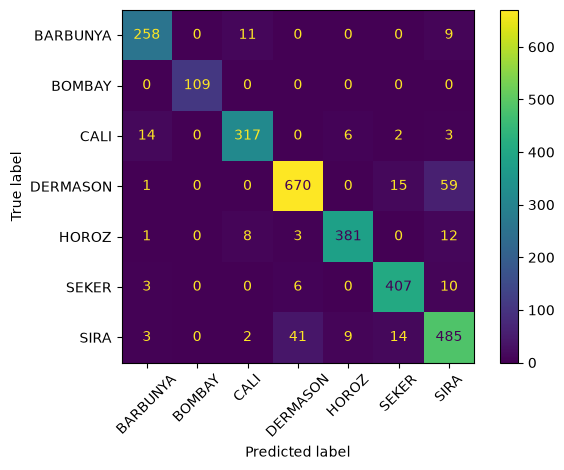

In [11]:
cm = confusion_matrix(y_test, y_pred, labels=mlp.classes_)
ConfusionMatrixDisplay(cm, display_labels=mlp.classes_).plot(xticks_rotation=45)
plt.tight_layout()
plt.show()

In [12]:
acc = accuracy_score(y_test, y_pred)
print(f"Acurácia:  {acc:.4f}")

Acurácia:  0.9189


In [13]:
f1 = f1_score(y_test, y_pred, average="macro")
print(f"F1:        {f1:.4f}")

F1:        0.9317


In [14]:
prec = precision_score(y_test, y_pred, average="macro")
print(f"Precisão:  {prec:.4f}")

Precisão:  0.9315


In [15]:
rec = recall_score(y_test, y_pred, average="macro")
print(f"Revocação: {rec:.4f}")

Revocação: 0.9323


### **3. Repita o treinamento da mesma rede anterior sem imprimir o passo a passo por 10 vezes**

In [16]:
REP = 10
seeds = range(65, 65 + REP)
n_jobs = min(8, cpu_count())
particoes = []

for seed in seeds:
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_base, y_base, test_size=0.3, stratify=y_base, random_state=seed
    )
    scaler = StandardScaler()
    X_tr_s = scaler.fit_transform(X_tr)
    X_te_s = scaler.transform(X_te)
    particoes.append((X_tr_s, X_te_s, y_tr, y_te))

In [17]:
import warnings
from sklearn.exceptions import ConvergenceWarning

def avalia_rede(camadas, ativ, solver, n_ep, i):
    X_tr_s, X_te_s, y_tr, y_te = particoes[i]
    rede = MLPClassifier(
        hidden_layer_sizes=camadas, activation=ativ, solver=solver,
        max_iter=n_ep, random_state=i
    )
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always", ConvergenceWarning)
        rede.fit(X_tr_s, y_tr)

    y_pred = rede.predict(X_te_s)
    return {
        "acc": accuracy_score(y_te, y_pred),
        "f1": f1_score(y_te, y_pred, average="macro", zero_division=0),
        "y_te": y_te,
        "y_pred": y_pred,
        "limite_atingido": any(issubclass(a.category, ConvergenceWarning) for a in avisos),
    }

def avalia_configuracao(nome, camadas, ativ, solver, n_ep):
    reps = [avalia_rede(camadas, ativ, solver, n_ep, i) for i in range(REP)]
    return (nome, solver, n_ep), reps

def avalia_arquiteturas(arquiteturas, solvers, epocas):
    with parallel_config(backend="loky", inner_max_num_threads=1):
        resultados = Parallel(n_jobs=n_jobs, verbose=5)(
            delayed(avalia_configuracao)(nome, camadas, ativ, solver, n_ep)
            for nome, (camadas, ativ) in arquiteturas.items()
            for solver in solvers
            for n_ep in epocas
        )
    return dict(resultados)

In [18]:
resultados_iniciais = avalia_arquiteturas({"Inicial": ((10,), "relu")}, ["adam", "sgd"], [300])
linhas = []
for (_, solver, _), reps in resultados_iniciais.items():
    accs = pd.Series([r["acc"] for r in reps])
    f1s = pd.Series([r["f1"] for r in reps])
    linhas.append({
        "solver": solver,
        "acc_média": accs.mean(), "acc_std": accs.std(ddof=1),
        "f1_média": f1s.mean(), "f1_std": f1s.std(ddof=1),
    })

resumo_inicial = pd.DataFrame(linhas).set_index("solver")
display(resumo_inicial.round(4))
delta = resumo_inicial.loc["adam", "f1_média"] - resumo_inicial.loc["sgd", "f1_média"]
melhor_solver = "Adam" if delta > 0 else "SGD"
if delta == 0:
    print("Os dois solvers empataram em F1 macro médio.")
else:
    print(f"{melhor_solver} teve F1 macro médio {abs(delta):.4f} maior com as mesmas partições.")
print("Os desvios padrão da tabela mostram a variação dos resultados entre as repetições.")

[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.


[Parallel(n_jobs=8)]: Done   2 out of   2 | elapsed:   21.2s finished


,acc_média,acc_std,f1_média,f1_std
solver,,,,
adam,0.9238,0.0041,0.9360,0.0042
sgd,0.9186,0.0027,0.9311,0.0026


Adam teve F1 macro médio 0.0049 maior com as mesmas partições.
Os desvios padrão da tabela mostram a variação dos resultados entre as repetições.


## Discussão

Nos passos anteriores, você avaliou o desempenho de uma única arquitetura de rede neural, com uma única camada oculta de 10 neurônios e função de ativação ReLU. O otimizador utilizado, seja o SGD ou o Adam, é o algoritmo que usa o gradiente do erro (calculado pela retropropagação) para atualizar os pesos da rede. Neste sentido, a escolha do otimizador é um hiperparâmetro: ela é definida antes do treinamento, não é aprendida a partir dos dados e controla como a rede será treinada. Também são hiperparâmetros a quantidade de camadas ocultas, o número de neurônios, a função de ativação, a quantidade de épocas, a taxa de aprendizado inicial, dentre outros. Já os parâmetros da rede são os pesos e os vieses, ajustados durante o treinamento.

Cabe salientar também que você efetuou o treinamento desta rede por 10 vezes e apresentou os resultados em termos de média ± desvio padrão. Lembre-se que em uma rede neural há a inicialização aleatória de pesos e, em consequência, o desempenho está sujeito a uma flutuação estocástica. Além disso, cada repetição utilizou uma nova partição holdout, o que introduz uma segunda fonte de variação. A execução múltipla das repetições reduz a influência de uma boa ou má "sorte" na escolha dos pesos iniciais e da partição, que poderia distorcer a conclusão no caso de uma única execução, e permite estimar a variabilidade do desempenho por meio do desvio padrão.

Você também aprendeu uma estratégia para escalonar os atributos para uma melhor convergência da rede. Utilize-a em todos os treinamentos e testes propostos a seguir.

## Propondo Novas Arquiteturas

Variando a arquitetura da rede (uma ou duas camadas ocultas, com diferentes números de neurônios em cada uma delas, e a função de ativação) e os hiperparâmetros solver (Adam ou SGD) e número máximo de épocas (100, 150 e 200), atenda ao que se pede:

1. Proponha 10 arquiteturas distintas de RNAs para o problema em questão, à sua escolha
2. Avalie cada uma das arquiteturas perante todas as combinações de hiperparâmetros (2 solvers × 3 números de épocas), repetindo cada treinamento/avaliação por 10 vezes  
    2.1 Cada repetição deve utilizar uma nova partição holdout 70/30 estratificada, com o escalonamento ajustado apenas com os dados de treino, e as mesmas 10 partições devem ser usadas em todas as configurações, para que a comparação seja justa  
    2.2 Ao todo, serão 60 configurações (10 arquiteturas × 2 solvers × 3 números de épocas) e 600 treinamentos
3. Como resultado da avaliação, apresente, com base no conjunto de teste:  
    3.1 As 3 melhores configurações (arquitetura + solver + número de épocas) no tocante ao F-Score (média macro) e à acurácia, considerando a média das 10 repetições (± desvio padrão)  
    3.2 Para cada uma dessas 3 configurações, a repetição em que houve o melhor desempenho: apresente a matriz de confusão e ilustre, para cada classe, os valores de VP (verdadeiros positivos), VN (verdadeiros negativos), FP (falsos positivos) e FN (falsos negativos)

1. Proponha 10 arquiteturas distintas de RNAs para o problema em questão, à sua escolha

In [19]:
arquiteturas = {
    "N1: (10) relu":         ((10,), "relu"),
    "N2: (32) relu":         ((32,), "relu"),
    "N3: (32) tanh":         ((32,), "tanh"),
    "N4: (32) logistic":     ((32,), "logistic"),
    "N5: (64) logistic":     ((64,), "logistic"),
    "N6: (16,8) relu":       ((16, 8), "relu"),
    "N7: (32,16) relu":      ((32, 16), "relu"),
    "N8: (32,16) tanh":      ((32,16), "tanh"),
    "N9: (32,16) logistic":  ((32, 16), "logistic"),
    "N10: (32) identity":    ((32,), "identity"),
}

2. Avalie cada uma das arquiteturas perante todas as combinações de hiperparâmetros (2 solvers × 3 números de épocas), repetindo cada treinamento/avaliação por 10 vezes  

In [20]:
solvers = ["adam", "sgd"]

In [21]:
epocas = [100, 150, 200]

2.1 Cada repetição deve utilizar uma nova partição holdout 70/30 estratificada, com o escalonamento ajustado apenas com os dados de treino, e as mesmas 10 partições devem ser usadas em todas as configurações, para que a comparação seja justa 

In [22]:
print(f"{len(particoes)} partições estratificadas, sementes de {seeds.start} a {seeds.stop - 1}.")

10 partições estratificadas, sementes de 65 a 74.


In [23]:
classes = sorted(y.unique())

In [24]:
resultados = avalia_arquiteturas(arquiteturas, solvers, epocas)

[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.


[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:   16.2s


[Parallel(n_jobs=8)]: Done  58 out of  60 | elapsed:  3.9min remaining:    7.9s


[Parallel(n_jobs=8)]: Done  60 out of  60 | elapsed:  3.9min finished


In [25]:
def resume_resultados(resultados, arquiteturas, estrategia):
    linhas = []
    for (nome, solver, n_ep), reps in resultados.items():
        camadas, ativ = arquiteturas[nome]
        accs = pd.Series([r["acc"] for r in reps])
        f1s = pd.Series([r["f1"] for r in reps])
        linhas.append({
            "arquitetura": nome, "camadas": camadas, "ativação": ativ,
            "estratégia": estrategia, "solver": solver, "épocas": n_ep,
            "repetições": len(reps),
            "acc_média": accs.mean(), "acc_std": accs.std(ddof=1),
            "f1_média": f1s.mean(), "f1_std": f1s.std(ddof=1),
            "limites_atingidos": sum(r["limite_atingido"] for r in reps),
        })
    return pd.DataFrame(linhas)

df_resultados = resume_resultados(resultados, arquiteturas, "Própria")

3. Como resultado da avaliação, apresente, com base no conjunto de teste:  
    3.1 As 3 melhores configurações (arquitetura + solver + número de épocas) no tocante ao F-Score (média macro) e à acurácia, considerando a média das 10 repetições (± desvio padrão)  

In [26]:
top_f1 = df_resultados.sort_values("f1_média", ascending=False).head(3)
top_acc = df_resultados.sort_values("acc_média", ascending=False).head(3)

def mostra(top, titulo):
    print(f"\n=== {titulo} ===")
    for _, r in top.iterrows():
        print(f"{r['arquitetura']} | {r['solver']} | {r['épocas']} ép. -> "
              f"F1 = {r['f1_média']:.4f} ± {r['f1_std']:.4f} | "
              f"Acc = {r['acc_média']:.4f} ± {r['acc_std']:.4f}")

mostra(top_f1, "Top 3 por F1 macro")
mostra(top_acc, "Top 3 por acurácia")


=== Top 3 por F1 macro ===
N7: (32,16) relu | adam | 200 ép. -> F1 = 0.9382 ± 0.0040 | Acc = 0.9261 ± 0.0043
N7: (32,16) relu | adam | 150 ép. -> F1 = 0.9378 ± 0.0032 | Acc = 0.9257 ± 0.0035
N2: (32) relu | adam | 150 ép. -> F1 = 0.9375 ± 0.0036 | Acc = 0.9257 ± 0.0035

=== Top 3 por acurácia ===
N7: (32,16) relu | adam | 200 ép. -> F1 = 0.9382 ± 0.0040 | Acc = 0.9261 ± 0.0043
N2: (32) relu | adam | 150 ép. -> F1 = 0.9375 ± 0.0036 | Acc = 0.9257 ± 0.0035
N7: (32,16) relu | adam | 150 ép. -> F1 = 0.9378 ± 0.0032 | Acc = 0.9257 ± 0.0035


3.2 Para cada uma dessas 3 configurações, a repetição em que houve o melhor desempenho: apresente a matriz de confusão e ilustre, para cada classe, os valores de VP (verdadeiros positivos), VN (verdadeiros negativos), FP (falsos positivos) e FN (falsos negativos)

In [27]:
def detalha(top, titulo, metrica="f1"):
    print(f"\n##### {titulo} #####")
    for _, r in top.iterrows():
        chave = (r["arquitetura"], r["solver"], r["épocas"])
        reps = resultados[chave]
        melhor = max(range(len(reps)), key=lambda k: reps[k][metrica])
        rep = reps[melhor]

        cm = confusion_matrix(rep["y_te"], rep["y_pred"], labels=classes)
        print(f"\n{chave} | melhor repetição = {melhor + 1} "
              f"(F1 = {rep['f1']:.4f}, Acc = {rep['acc']:.4f})")
        print(pd.DataFrame(cm, index=classes, columns=classes))

        total = cm.sum()
        VP = cm.diagonal()
        FP = cm.sum(axis=0) - VP
        FN = cm.sum(axis=1) - VP
        VN = total - VP - FP - FN
        print(pd.DataFrame({"VP": VP, "VN": VN, "FP": FP, "FN": FN}, index=classes))

In [28]:
detalha(top_f1, "Detalhe: top 3 por F1")
detalha(top_acc, "Detalhe: top 3 por acurácia", metrica="acc")


##### Detalhe: top 3 por F1 #####

('N7: (32,16) relu', 'adam', 200) | melhor repetição = 1 (F1 = 0.9427, Acc = 0.9314)
          BARBUNYA  BOMBAY  CALI  DERMASON  HOROZ  SEKER  SIRA
BARBUNYA       258       0    14         0      0      4     2
BOMBAY           0     109     0         0      0      0     0
CALI             7       0   321         0      7      2     5
DERMASON         0       0     0       690      0     13    42
HOROZ            1       0     7         2    383      0    12
SEKER            2       0     0         4      0    412     8
SIRA             0       0     0        50      5      9   490
           VP    VN  FP  FN
BARBUNYA  258  2571  10  20
BOMBAY    109  2750   0   0
CALI      321  2496  21  21
DERMASON  690  2058  56  55
HOROZ     383  2442  12  22
SEKER     412  2405  28  14
SIRA      490  2236  69  64

('N7: (32,16) relu', 'adam', 150) | melhor repetição = 1 (F1 = 0.9425, Acc = 0.9314)
          BARBUNYA  BOMBAY  CALI  DERMASON  HOROZ  SEKER  SIRA
BA

## Estimando o número de neurônios

Um dos problemas de pesquisa com redes neurais artificiais consiste na determinação do número de neurônios em sua arquitetura. Embora não seja possível definir a priori qual rede neural é adequada para um problema, pois isto só pode ser determinado empiricamente, mediante a avaliação de várias arquiteturas, há regras na literatura que sugerem o número de neurônios escondidos, tal como a regra da Pirâmide Geométrica, dada a seguir:

$$N_h = \alpha \cdot \sqrt{N_i \cdot N_o},$$

em que $N_h$ é o número de neurônios ocultos (a serem distribuídos em uma ou duas camadas ocultas), $N_i$ é o número de neurônios na camada de entrada e $N_o$ é o número de neurônios na camada de saída. Como $N_h$ deve ser um número inteiro, arredonde o resultado para o inteiro mais próximo.

1. Consulte a documentação da classe MLPClassifier (disponível em https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html) e obtenha os valores de $N_i$ e $N_o$ para a base _Dry Bean_, considerando o número de atributos preditores e o número de classes do problema.
2. Teste os valores de $\alpha$ como sendo iguais a $0.5$, $2$ e $3$.
3. Proponha pelo menos 30 redes neurais segundo a regra da pirâmide geométrica e teste-as nos mesmos termos estabelecidos anteriormente (solver, épocas, 10 repetições com as mesmas partições holdout, escalonamento, etc.)  
    3.1 Apresente as top-3 melhores redes no tocante à F-Score e Acurácia, com base no conjunto de teste

### Respostas

Na documentação, na seção de atributos, dois itens são úteis para a resposta:  
- n_features_in_: número de features vistas durante o fit.
- n_outputs_: número de neurônios na camada de saída

Logo, são Ni (número de entradas, ou seja, número de atributos preditores) e No (número de saídas, ou seja o número de classes) respectivamente.

In [29]:
# Testando alphas
Ni, No = 16, 7
alphas = [0.5, 2, 3]

In [30]:
for alpha in alphas:
    Nh = round(alpha* (Ni * No) ** 0.5)
    print(f"a = {alpha} -> Nh = {Nh}")

a = 0.5 -> Nh = 5
a = 2 -> Nh = 21
a = 3 -> Nh = 32


A regra da pirâmide geométrica (proposta por Timothy Masters em 1993) é uma heurística empírica usada para definir a quantidade ideal de neurônios nas camadas ocultas de uma rede neural artificial (especialmente em redes Multilayer Perceptron - MLP).

In [31]:
arq_piramide = {}
for alpha in alphas:
    Nh = round(alpha * (Ni * No) ** 0.5)

    formatos = {
        "1c":      (Nh,),
        "2c 75/25": (round(Nh * 0.75), Nh - round(Nh * 0.75)),
        "2c 50/50": (round(Nh * 0.50), Nh - round(Nh * 0.50)),
        "2c 25/75": (round(Nh * 0.25), Nh - round(Nh * 0.25)),
    }

    for nome_f, camadas in formatos.items():
        for ativ in ["relu", "tanh"]:
            arq_piramide[f"α={alpha} Nh={Nh} {nome_f} {camadas} {ativ}"] = (camadas, ativ)

    arq_piramide[f"α={alpha} Nh={Nh} 1c {formatos['1c']} logistic"] = (formatos["1c"], "logistic")
    arq_piramide[f"α={alpha} Nh={Nh} 2c 50/50 {formatos['2c 50/50']} logistic"] = (formatos["2c 50/50"], "logistic")

In [32]:
print(len(arq_piramide), "redes") 
for nome, (camadas, ativ) in arq_piramide.items():
    print(nome)

30 redes
α=0.5 Nh=5 1c (5,) relu
α=0.5 Nh=5 1c (5,) tanh
α=0.5 Nh=5 2c 75/25 (4, 1) relu
α=0.5 Nh=5 2c 75/25 (4, 1) tanh
α=0.5 Nh=5 2c 50/50 (2, 3) relu
α=0.5 Nh=5 2c 50/50 (2, 3) tanh
α=0.5 Nh=5 2c 25/75 (1, 4) relu
α=0.5 Nh=5 2c 25/75 (1, 4) tanh
α=0.5 Nh=5 1c (5,) logistic
α=0.5 Nh=5 2c 50/50 (2, 3) logistic
α=2 Nh=21 1c (21,) relu
α=2 Nh=21 1c (21,) tanh
α=2 Nh=21 2c 75/25 (16, 5) relu
α=2 Nh=21 2c 75/25 (16, 5) tanh
α=2 Nh=21 2c 50/50 (10, 11) relu
α=2 Nh=21 2c 50/50 (10, 11) tanh
α=2 Nh=21 2c 25/75 (5, 16) relu
α=2 Nh=21 2c 25/75 (5, 16) tanh
α=2 Nh=21 1c (21,) logistic
α=2 Nh=21 2c 50/50 (10, 11) logistic
α=3 Nh=32 1c (32,) relu
α=3 Nh=32 1c (32,) tanh
α=3 Nh=32 2c 75/25 (24, 8) relu
α=3 Nh=32 2c 75/25 (24, 8) tanh
α=3 Nh=32 2c 50/50 (16, 16) relu
α=3 Nh=32 2c 50/50 (16, 16) tanh
α=3 Nh=32 2c 25/75 (8, 24) relu
α=3 Nh=32 2c 25/75 (8, 24) tanh
α=3 Nh=32 1c (32,) logistic
α=3 Nh=32 2c 50/50 (16, 16) logistic


In [33]:
resultados_p = avalia_arquiteturas(arq_piramide, solvers, epocas)
df_p = resume_resultados(resultados_p, arq_piramide, "Pirâmide Geométrica")

[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.


[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:   15.6s


[Parallel(n_jobs=8)]: Done  56 tasks      | elapsed:  2.9min


[Parallel(n_jobs=8)]: Done 146 tasks      | elapsed:  9.1min


[Parallel(n_jobs=8)]: Done 180 out of 180 | elapsed: 11.7min finished


In [34]:
def show(top, titulo):
    print(f"\n=== {titulo} ===")
    for _, r in top.iterrows():
        print(f"{r['arquitetura']} | {r['solver']} | {r['épocas']} ép. -> "
              f"F1 = {r['f1_média']:.4f} ± {r['f1_std']:.4f} | "
              f"Acc = {r['acc_média']:.4f} ± {r['acc_std']:.4f}")

top_f1_p = df_p.sort_values("f1_média", ascending=False).head(3)
top_acc_p = df_p.sort_values("acc_média", ascending=False).head(3)

show(top_f1_p, "Top 3 por F1 macro")
show(top_acc_p, "Top 3 por acurácia")


=== Top 3 por F1 macro ===
α=3 Nh=32 2c 75/25 (24, 8) relu | adam | 200 ép. -> F1 = 0.9378 ± 0.0037 | Acc = 0.9259 ± 0.0039
α=3 Nh=32 1c (32,) relu | adam | 150 ép. -> F1 = 0.9375 ± 0.0036 | Acc = 0.9257 ± 0.0035
α=3 Nh=32 1c (32,) relu | adam | 200 ép. -> F1 = 0.9374 ± 0.0033 | Acc = 0.9256 ± 0.0032

=== Top 3 por acurácia ===
α=3 Nh=32 2c 75/25 (24, 8) relu | adam | 200 ép. -> F1 = 0.9378 ± 0.0037 | Acc = 0.9259 ± 0.0039
α=3 Nh=32 1c (32,) relu | adam | 150 ép. -> F1 = 0.9375 ± 0.0036 | Acc = 0.9257 ± 0.0035
α=3 Nh=32 2c 50/50 (16, 16) relu | adam | 200 ép. -> F1 = 0.9372 ± 0.0039 | Acc = 0.9257 ± 0.0045


## Considerações Parciais

1. É possível identificar uma rede com desempenho superior às demais? 
2. Qual estratégia mostrou-se mais produtiva para a obtenção de boas arquiteturas (Estratégia Própria ou Pirâmide Geométrica)? Por quê?
3. Um número maior de épocas trouxe melhorias? Justifique com os resultados obtidos, considerando também cada um dos solvers (Adam e SGD)
4. Qual a maior dificuldade de resolução do problema proposto perante as RNAs?

In [35]:
todos = pd.concat([df_resultados, df_p], ignore_index=True)
ranking = todos.sort_values(["f1_média", "acc_média"], ascending=False)
top_6 = ranking.drop_duplicates(["camadas", "ativação"]).head(6)
top_6.to_csv(raiz / "Notebooks" / "top_6_rnas.csv", index=False)

print("Melhor configuração de cada estratégia:")
display(ranking.drop_duplicates("estratégia").round(4))

print("F1 macro médio das configurações por solver e limite de épocas:")
display(todos.groupby(["solver", "épocas"])["f1_média"].mean().unstack().round(4))

print("Seis arquiteturas selecionadas para a etapa 3:")
display(top_6.round(4))

Melhor configuração de cada estratégia:


,arquitetura,camadas,ativação,estratégia,solver,épocas,repetições,acc_média,acc_std,f1_média,f1_std,limites_atingidos
38,"N7: (32,16) relu","(32, 16)",relu,Própria,adam,200,10,0.9261,0.0043,0.9382,0.0040,9
194,"α=3 Nh=32 2c 75/25 (24, 8) relu","(24, 8)",relu,Pirâmide Geométrica,adam,200,10,0.9259,0.0039,0.9378,0.0037,7


F1 macro médio das configurações por solver e limite de épocas:


épocas,100,150,200
solver,,,
adam,0.8371,0.8546,0.8670
sgd,0.7291,0.7587,0.7816


Seis arquiteturas selecionadas para a etapa 3:


,arquitetura,camadas,ativação,estratégia,solver,épocas,repetições,acc_média,acc_std,f1_média,f1_std,limites_atingidos
38,"N7: (32,16) relu","(32, 16)",relu,Própria,adam,200,10,0.9261,0.0043,0.9382,0.0040,9
194,"α=3 Nh=32 2c 75/25 (24, 8) relu","(24, 8)",relu,Pirâmide Geométrica,adam,200,10,0.9259,0.0039,0.9378,0.0037,7
7,N2: (32) relu,"(32,)",relu,Própria,adam,150,10,0.9257,0.0035,0.9375,0.0036,10
122,"α=2 Nh=21 1c (21,) relu","(21,)",relu,Pirâmide Geométrica,adam,200,10,0.9256,0.0041,0.9374,0.0037,9
206,"α=3 Nh=32 2c 50/50 (16, 16) relu","(16, 16)",relu,Pirâmide Geométrica,adam,200,10,0.9257,0.0045,0.9372,0.0039,8
32,"N6: (16,8) relu","(16, 8)",relu,Própria,adam,200,10,0.9253,0.0041,0.9371,0.0039,9


Usamos F1 macro para comparar as estratégias, pois cada variedade tem o mesmo peso na métrica. Na tabela por solver e limite de épocas, cada média considera todas as arquiteturas testadas naquela combinação. A coluna de limites atingidos indica quantas redes chegaram ao limite de épocas com aviso de convergência.

1. A configuração com maior média foi **N7: (32,16) relu**, com adam e limite de 200 épocas. Ela obteve F1 macro de 0.9382 ± 0.0040. O ranking descreve os holdouts usados no experimento.
2. As melhores médias por estratégia foram 0.9382 (Própria) e 0.9378 (Pirâmide Geométrica). A comparação usa a mesma métrica e as mesmas partições nas duas estratégias.
3. Com 100, 150 e 200 épocas, as médias globais foram 0.8371, 0.8546, 0.8670 para Adam e 0.7291, 0.7587, 0.7816 para SGD. Essas médias descrevem o efeito observado no conjunto de arquiteturas, e os resultados de cada configuração mostram como o efeito varia entre redes.
4. A maior dificuldade é separar variedades com medidas geométricas parecidas. As matrizes de confusão mostram quais pares de classes são mais confundidos.